In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

In [56]:
files = [
    "data/Unfallorte2020_LinRef.csv",
    "data/Unfallorte_2021_LinRef.txt",
    "data/Unfallorte2022_LinRef.csv",
    "data/Unfallorte2023_LinRef.csv",
    "data/Unfallorte2024_LinRef.csv",
    "data/Unfallorte_2025_LR_BasisDLM.csv",
]

frames = []
for f in files:
    d = pd.read_csv(f, sep=";", decimal=",")
    d = d.rename(columns={"IstStrassenzustand": "STRZUSTAND"})   # ab 2021 anders benannt
    d = d.drop(columns=["OBJECTID", "OID_", "UIDENTSTLAE", "PLST"], errors="ignore")
    frames.append(d)

df = pd.concat(frames, ignore_index=True)

/var/folders/l_/gx9nbvqs3s181hk13j3hthlw0000gp/T/ipykernel_72406/287246640.py:12: DtypeWarning: Columns (23: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f, sep=";", decimal=",")
/var/folders/l_/gx9nbvqs3s181hk13j3hthlw0000gp/T/ipykernel_72406/287246640.py:12: DtypeWarning: Columns (1: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f, sep=";", decimal=",")
/var/folders/l_/gx9nbvqs3s181hk13j3hthlw0000gp/T/ipykernel_72406/287246640.py:12: DtypeWarning: Columns (0: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f, sep=";", decimal=",")


In [59]:
print(df.shape) 
print(df.isna().sum().sum())                     
print(df["UJAHR"].value_counts().sort_index()) 
print(df.groupby("UJAHR")["ULAND"].nunique())    
print(df.groupby("UJAHR")["UMONAT"].nunique())    

(1543886, 23)
0
UJAHR
2020    237994
2021    238826
2022    256492
2023    269048
2024    268519
2025    273007
Name: count, dtype: int64
UJAHR
2020    16
2021    16
2022    16
2023    16
2024    16
2025    16
Name: ULAND, dtype: int64
UJAHR
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
Name: UMONAT, dtype: int64


In [60]:
print(df.dtypes)

ULAND            int64
UREGBEZ          int64
UKREIS           int64
UGEMEINDE        int64
UJAHR            int64
UMONAT           int64
USTUNDE          int64
UWOCHENTAG       int64
UKATEGORIE       int64
UART             int64
UTYP1            int64
ULICHTVERH       int64
IstRad           int64
IstPKW           int64
IstFuss          int64
IstKrad          int64
IstGkfz          int64
IstSonstige      int64
LINREFX        float64
LINREFY        float64
XGCSWGS84      float64
YGCSWGS84      float64
STRZUSTAND       int64
dtype: object


In [64]:
df_rad = df[df["IstRad"] == 1].copy()
print(len(df_rad))

500799


1. Zeitliche Entwicklung

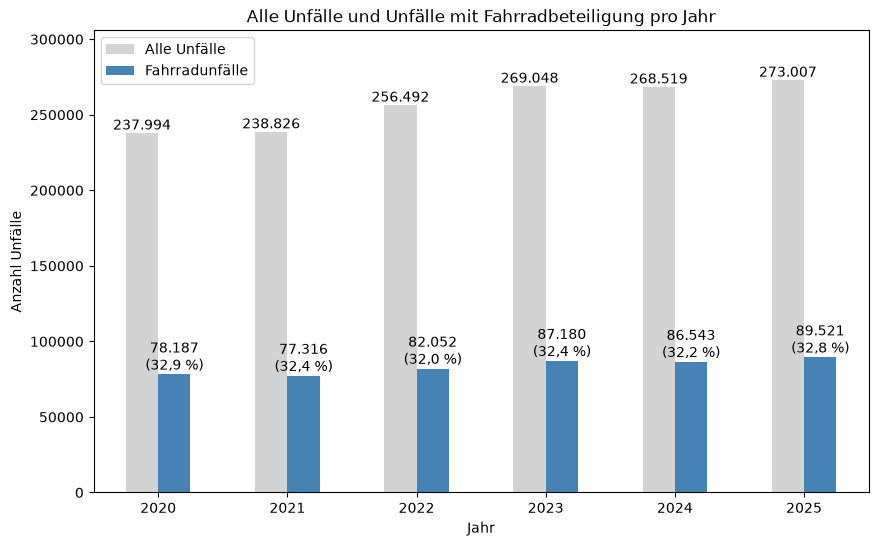

In [73]:
#  1.1 Entwicklung der Fahrradunfälle pro Jahr

alle_year = df.groupby("UJAHR").size()
rad_year = df_rad.groupby("UJAHR").size()
anteil = (rad_year / alle_year * 100).round(1)

vergleich = pd.DataFrame({
    "Alle Unfälle": alle_year,
    "Fahrradunfälle": rad_year,
})

ax = vergleich.plot(kind="bar", figsize=(10, 6), color=["lightgray", "steelblue"])


ax.bar_label(ax.containers[0], labels=[f"{v:,}".replace(",", ".") for v in alle_year])
ax.bar_label(
    ax.containers[1],
    labels=[f"{v:,}".replace(",", ".") + f"\n({str(a).replace('.', ',')} %)"
            for v, a in zip(rad_year, anteil)]
)

plt.title("Alle Unfälle und Unfälle mit Fahrradbeteiligung pro Jahr")
plt.xlabel("Jahr")
plt.ylabel("Anzahl Unfälle")
plt.xticks(rotation=0)
plt.ylim(0, alle_year.max() * 1.12)
plt.legend();

Zwischen 2020 und 2025 ist die Zahl der Unfälle mit Fahrradbeteiligung von 78.187 auf 89.521 gestiegen, das entspricht einem Plus von rund 14,5 %. Den niedrigsten Wert gab es 2021 (77.316), den höchsten 2025 (89.521). Die Entwicklung verlief nicht gleichmäßig: Auf einen leichten Rückgang 2021 (−1,1 %) folgten zwei Anstiege 2022 und 2023 (jeweils rund +6 %), danach ein minimaler Rückgang 2024 (−0,7 %) und erneut ein Anstieg 2025 (+3,4 %).

Der Anteil der Fahrradunfälle an allen Unfällen mit Personenschaden blieb in allen Jahren nahezu konstant bei 32,0 bis 32,9 %. Die Fahrradunfälle sind also nicht überproportional gewachsen, sondern im Gleichschritt mit der Gesamtzahl der Unfälle (von 237.994 auf 273.007, ebenfalls rund +15 %). Die Daten enthalten keine Angaben zur tatsächlichen Fahrradnutzung, daher lässt sich aus der Entwicklung nicht ableiten, ob Radfahren riskanter geworden ist.